# Detección Inteligente de Arritmias con Datos ECG
*Ejercicio de Feedback 2*

**Asignatura:** Matemáticas y Estadística para la IA  
**Autor:** Tania Évora  
**Fecha:** Enero 2026  

Este notebook presenta el análisis estadístico y el desarrollo de modelos de clasificación supervisada para la detección de latidos cardíacos anómalos a partir de señales ECG, con aplicación en sistemas de monitorización mediante dispositivos wearables.

## 1. Introducción y contexto
La detección temprana de arritmias cardíacas es un problema de gran relevancia clínica, especialmente en poblaciones de riesgo como personas mayores de 60 años.
Gracias a los avances en sensores portátiles y aprendizaje automático, es posible analizar señales ECG en tiempo casi real y generar alertas inteligentes.

El objetivo de este trabajo es analizar señales ECG individuales y desarrollar modelos de clasificación capaces de distinguir entre latidos normales y anómalos, combinando estadística descriptiva, reducción de dimensionalidad y modelos de aprendizaje automático.

## 2. Carga de datos y librerías
En esta sección se cargan los conjuntos de datos `mitbih_train.csv` y `mitbih_test.csv` del ECG Heartbeat Categorization Dataset, así como las librerías necesarias para el análisis y desarrollo de modelos.

In [74]:
# Librerías básicas
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística y ML
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
from scipy import stats as sp_stats

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_score, recall_score

colors = ["#78c2ad", "#f3969a", "#f2d388", "#84a59d", "#e7a9c9"] 
model_colors = ["#9ecae1", "#b5e2b3", "#f7c59f", "#d7bce8"]

El dataset cuenta con 187 valores numéricos por latido (señal ECG a 125 Hz) y 1 etiqueta de clase. Los tipos de latido se distinguen en 5 clases: Normal (0), Supraventricular (1), Ventricular (2), Fusión (3), Ruido (4)

In [75]:
df_train = pd.read_csv('data/mitbih_train.csv', header=None)
df_test = pd.read_csv('data/mitbih_test.csv', header=None)

print(f'Dimensiones del conjunto de entrenamiento: {df_train.shape}')
print(f'Dimensiones del conjunto de prueba: {df_test.shape}')

Dimensiones del conjunto de entrenamiento: (87554, 188)
Dimensiones del conjunto de prueba: (21892, 188)


In [76]:
# Separación de características (187 columnas) y etiqueta
x_train = df_train.iloc[:, :-1]  # 187 valores de señal
y_train = df_train.iloc[:, -1]   # Etiqueta de clase

x_test = df_test.iloc[:, :-1]
y_test = df_test.iloc[:, -1]

# Diccionario de etiquetas
class_labels = {
    0: "Normal (N)",
    1: "Supraventricular (S)",
    2: "Ventricular (V)",
    3: "Fusión (F)",
    4: "Ruido (Q)"
}

# Versión binaria: Normal (0) vs Anómalo (1, 2, 3, 4)
y_train_binary = (y_train != 0).astype(int)
y_test_binary = (y_test != 0).astype(int)

print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")

x_train: (87554, 187)
y_train: (87554,)


## 3. Exploración Inicial y Análisis Descriptivo (EDA)
El objetivo de esta sección es conocer la estructura del dataset y detectar patrones, anomalías o características relevantes.

### 3.1 Estructura del dataset
Como se mencionó previamente, el dataset cuenta con 187 valores numéricos y una etiqueta de clase, en este caso, todos de tipo flotante tal como se muestra a continuación. Se incluye una vista de los 5 primeros registros, para comprobar estos valores.

In [77]:
df_train.info()
df_train.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87554 entries, 0 to 87553
Columns: 188 entries, 0 to 187
dtypes: float64(188)
memory usage: 125.6 MB


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


A continuación se muestra un resumen estadístico de las 187 columnas. El **count** confirma los 87554 registros en cada columna. La **media** es más alta en las primeras columnas y va disminuyendo progresivamente, mientras que la **desviación estándar** se mantiene relativamente estable. Los valores **mínimo (0) y máximo (1)** en todas las columnas confirman que los datos están normalizados, tal como se indica en el enunciado.

In [78]:
df_train.describe()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
count,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,...,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000
mean,0.890360,0.758160,0.423972,0.219104,0.201127,0.210399,0.205808,0.201773,0.198691,0.196757,...,0.005025,0.004628,0.004291,0.003945,0.003681,0.003471,0.003221,0.002945,0.002807,0.473376
std,0.240909,0.221813,0.227305,0.206878,0.177058,0.171909,0.178481,0.177240,0.171778,0.168357,...,0.044154,0.042089,0.040525,0.038651,0.037193,0.036255,0.034789,0.032865,0.031924,1.143184
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.921922,0.682486,0.250969,0.048458,0.082329,0.088416,0.073333,0.066116,0.065000,0.068639,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.991342,0.826013,0.429472,0.166000,0.147878,0.158798,0.145324,0.144424,0.150000,0.148734,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.910506,0.578767,0.341727,0.258993,0.287628,0.298237,0.295391,0.290832,0.283636,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


### 3.2 Distribución de clases
El siguiente diagrama de barras muestra la distribución de registros por cada tipo de latido. Se observa un **desbalance marcado** entre las clases: aproximadamente el 83% de los registros corresponden a *latidos normales* (clase 0). Este comportamiento es habitual en escenarios clínicos reales, donde las arritmias son casos menos frecuentes. Este desbalance deberá tenerse en cuenta en el modelado, ya que puede afectar al rendimiento de los clasificadores, especialmente en la detección de las clases minoritarias.

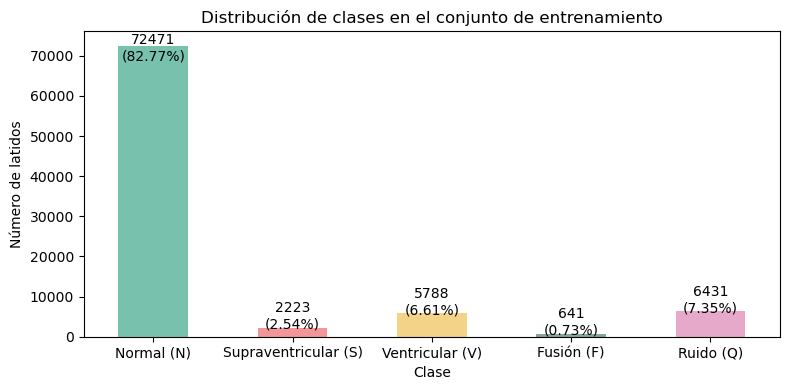

In [79]:
# Diagrama de barras de la distribución de clases
class_count = y_train.value_counts().sort_index()
class_percent = y_train.value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(8, 4))
class_count.plot(kind='bar', color=colors)
plt.title('Distribución de clases en el conjunto de entrenamiento')
plt.xlabel('Clase')
plt.ylabel('Número de latidos')
for i, count in enumerate(class_count):
  percent = class_percent[i]
  plt.text(i, count * 0.95, f'{count}\n({percent:.2f}%)', ha='center')
plt.xticks(ticks=range(5), labels=[class_labels[i] for i in range(5)], rotation=0)
plt.tight_layout()
plt.show()

En este caso, se agrupas todas las clases anómalas (Supraventricular, Ventricular, Fusión y Ruido) en una única categoría denominada *Anómalo*. Como se trata de los mismos datos, la clase *Normal* mantiene el 82.77% de los registros, mientras que la clase *Anómalo* representa solo el 17.23%. Incluso unificando las arritmias, el **desbalance sigue siendo muy marcado**, lo que se debe tener en cuenta en la fase de modelado.

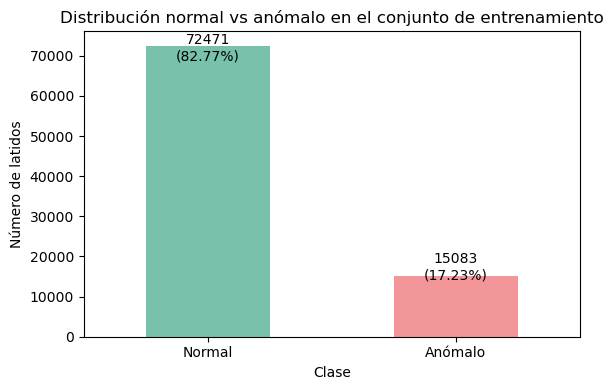

In [80]:
# Diagrama de barras de la distribución binaria
class_count = y_train_binary.value_counts().sort_index()
class_percent = y_train_binary.value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(6, 4))
class_count.plot(kind='bar', color=colors[:2])
plt.title('Distribución normal vs anómalo en el conjunto de entrenamiento')
plt.xlabel('Clase')
plt.ylabel('Número de latidos')
for i, count in enumerate(class_count): # modificar para que haya mas espacio
  percent = class_percent[i]
  plt.text(i, count * 0.95, f'{count}\n({percent:.2f}%)', ha='center')
plt.xticks(ticks=range(2), labels=['Normal', 'Anómalo'], rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Estadística descriptiva de las señales
Se amplía el análisis estadístico incorporando medidas de forma de la distribución para cada una de las 5 clases. La **media** varía en función de la clase: Fusión presenta los valores más bajos (0.11), mientras que ruido y Ventricular tienen los más altos (~0.25). La **desviación estándar** también cambia, siendo más alta en la clase Ventricular (0.21) y la más baja en Fusión (0.11). Las clases Normal y Supraventricular son similares en cuanto a media y desviación.

Respecto a las medidas de forma, todas las clases presentan **asimetría positiva**, lo que indica distribuciones con cola a la derecha, aunque se observa una notable diferencia en la magnitud de dicha asimetría entre las clases.

In [81]:
# Estadísticos globales de todas las señales
class_stats = {label: x_train[y_train == label].describe().T for label in range(5)}

stats_comparison = pd.DataFrame({
  'Media': [], 
  'Desviación_Estándar': [], 
  'Mínimo': [], 
  'Máximo': [], 
  'Asimetría': [], 
  'Curtosis': []
})

for label, stats in class_stats.items():
  stats_comparison.loc[class_labels[label]] = [
    stats['mean'].mean(),
    stats['std'].mean(),
    stats['min'].min(),
    stats['max'].max(),
    x_train[y_train == label].skew().mean(),
    x_train[y_train == label].kurtosis().mean()
  ]
print(stats_comparison.T)

                     Normal (N)  Supraventricular (S)  Ventricular (V)  \
Media                  0.161896              0.194778         0.243849   
Desviación_Estándar    0.167823              0.161634         0.212493   
Mínimo                 0.000000              0.000000         0.000000   
Máximo                 1.000000              1.000000         1.000000   
Asimetría              3.437708              1.396150         1.416216   
Curtosis              33.774411              3.948963         3.929700   

                     Fusión (F)    Ruido (Q)  
Media                  0.107253     0.250854  
Desviación_Estándar    0.107165     0.134158  
Mínimo                 0.000000     0.000000  
Máximo                 1.000000     1.000000  
Asimetría              8.201759    20.655660  
Curtosis             121.729985  1576.076614  


Analizandolo desde la versión binaria, se observa que las señales anómalas presentan en promedio **medias más altas** y **mayor desviación estándar** en comparación con las normales, lo que indica mayor variabilidad en las amplitudes de los latidos anómalos.

Respecto a la **forma de las distribuciones** ambos grupos presentan **asimetría positiva** (colas a la derecha) y **leptocurtosis** (colas pesadas y pico pronunciado), pero estos efectos son mucho más **extremos en los latidos normales**. Esto puede relacionarse con el análisis anterior, ya que al combinar distribuciones con características muy distintas (desd Supraventricular con curtosis ~4 hasta Ruido con ~1576), se obtienen valores más moderados. En cambio, la clase Normal mantiene un comportamiendo homogéneo con asimetría y curtosis elevadas, y una distribución más concentrada. 

In [82]:
# Comparar estadísticos entre grupos Normal vs Anómalo
stats_normal = x_train[y_train == 0]
stats_anomalous = x_train[y_train != 0]
stats_comparison = pd.DataFrame({
  'Media' : [stats_normal.mean().mean(), stats_anomalous.mean().mean()],
  'Desviación_Estándar' : [stats_normal.std().mean(), stats_anomalous.std().mean()],
  'Mínimo' : [stats_normal.min().min(), stats_anomalous.min().min()],
  'Máximo' : [stats_normal.max().max(), stats_anomalous.max().max()],
  'Asimetría' : [stats_normal.skew().mean(), stats_anomalous.skew().mean()],
  'Curtosis' : [stats_normal.kurtosis().mean(), stats_anomalous.kurtosis().mean()]
}, index=['Normal', 'Anómalo'])
print(stats_comparison.T)

                        Normal   Anómalo
Media                 0.161896  0.233798
Desviación_Estándar   0.167823  0.188087
Mínimo                0.000000  0.000000
Máximo                1.000000  1.000000
Asimetría             3.437708  1.781297
Curtosis             33.774411  7.661344


### 3.4 Visualizaciones
Para completar el análisis estadístico, se incluyen gráficas que permitan observar las diferencias entre clases. Comenzando por un boxplot para comparar la distribución de la **amplitud media** de cada latido:
- **Menor amplitud:** Las clases Fusión y Normal presentan las medianas más bajas (0.10 a 0.13). La Normal presenta una alta densidad de valores atípicos superiores, que puede deberse a la mayor concentración de la distribución.
- **Mayor amplitud y varianza:** Las clases Ventricular y Ruido tiene nmedianas más altas y cajas más amplias, indicando una mayor dispersión de sus valores.

A pesar de las diferencias en las medianas, existe superposición entre todas las clases. Por esto, se concluye que la amplitud media no será una característica discriminativa válida por sí sola.

C:\Users\tania\AppData\Local\Temp\ipykernel_19596\901280077.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=[class_labels[i] for i in range(5)], patch_artist=True, medianprops=dict(color='black'))


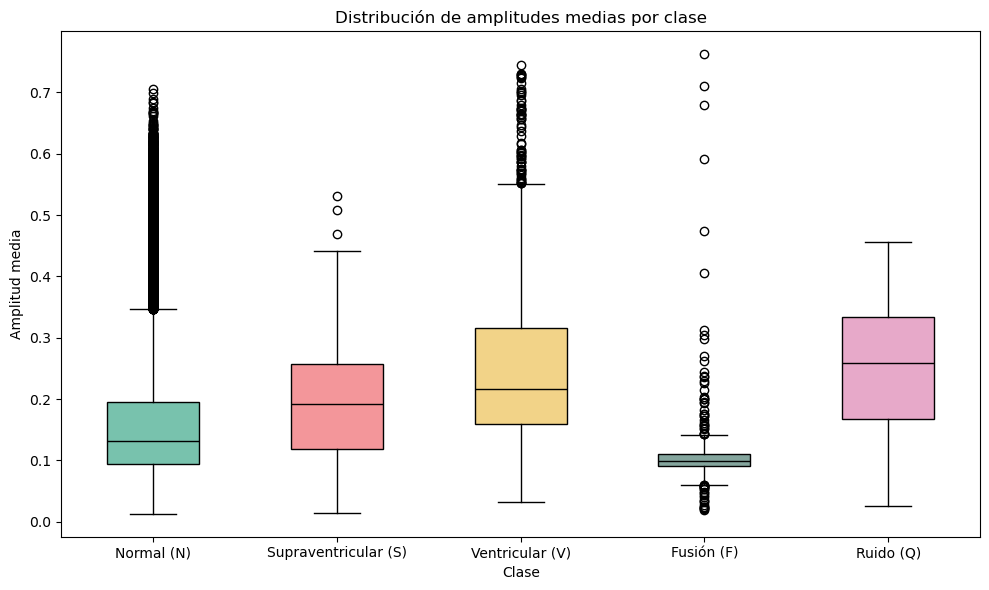

In [83]:
# Boxplot comparativo
fig, ax = plt.subplots(figsize=(10, 6))

data_to_plot = [x_train[y_train == cls].mean(axis=1) for cls in range(5)]

bp = ax.boxplot(data_to_plot, labels=[class_labels[i] for i in range(5)], patch_artist=True, medianprops=dict(color='black'))
for i, box in enumerate(bp['boxes']):
    box.set(facecolor=colors[i])

ax.set_ylabel('Amplitud media')
ax.set_xlabel('Clase')
ax.set_title('Distribución de amplitudes medias por clase')
plt.tight_layout()
plt.show()

Se muestra un ejemplo de señal ECG por cada clase. El latido **normal** presenta picos más marcados y definidos. En cambio, las señales **anómalas** muestran patrones menos estables, con picos más anchos y menos estables según el tipo de arritmia.

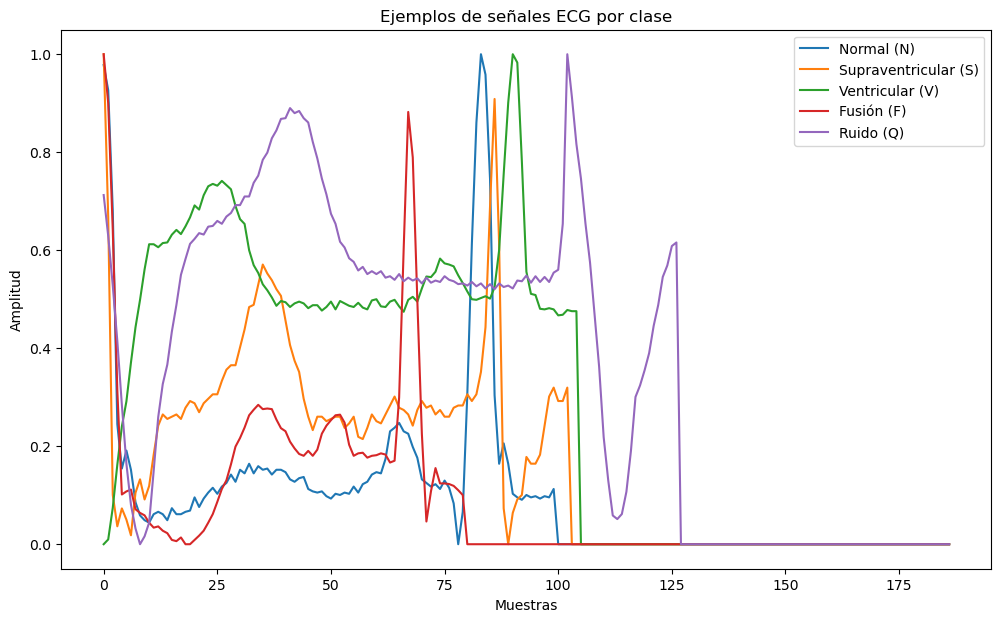

In [84]:
plt.figure(figsize=(12, 7))
for cls in range(5):
  idx = y_train[y_train == cls].index[0]
  plt.plot(x_train.loc[idx], label=class_labels[cls])

plt.title('Ejemplos de señales ECG por clase')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.legend()
plt.show()

Por último, se representa el **latido promedio** para analizar la morfología temporal de cada clase: 
- **Patrón Normal:** Es la señal más estable. Muestra un pico inicial pronunciado (alta amplitud) seguido de un decaimiento suave y estable hacia el cero, con pocas fluctuaciones intermedias.
- **Patrón Ventricular:** Difiere claramente del normal. Su pico inicial es más bajo, pero la señal mantiene una amplitud media más ancha durante más tiempo, indicando una morfología distinta y no solo una variación en intesidad.
- **Otras anomalías (S, F, Q):** Presentan mayor irregularidad. Las clases Supraventricular, Fusión y Ruido, exhiben múltiples picos y oscilaciones a lo largo del tiempo, reflejando una mayor inestabilidad en la señal comparada con las otras dos clase.

Estas observaciones sugieren que la forma de la onda a lo largo del tiempo aportan información adicional para la clasificación.

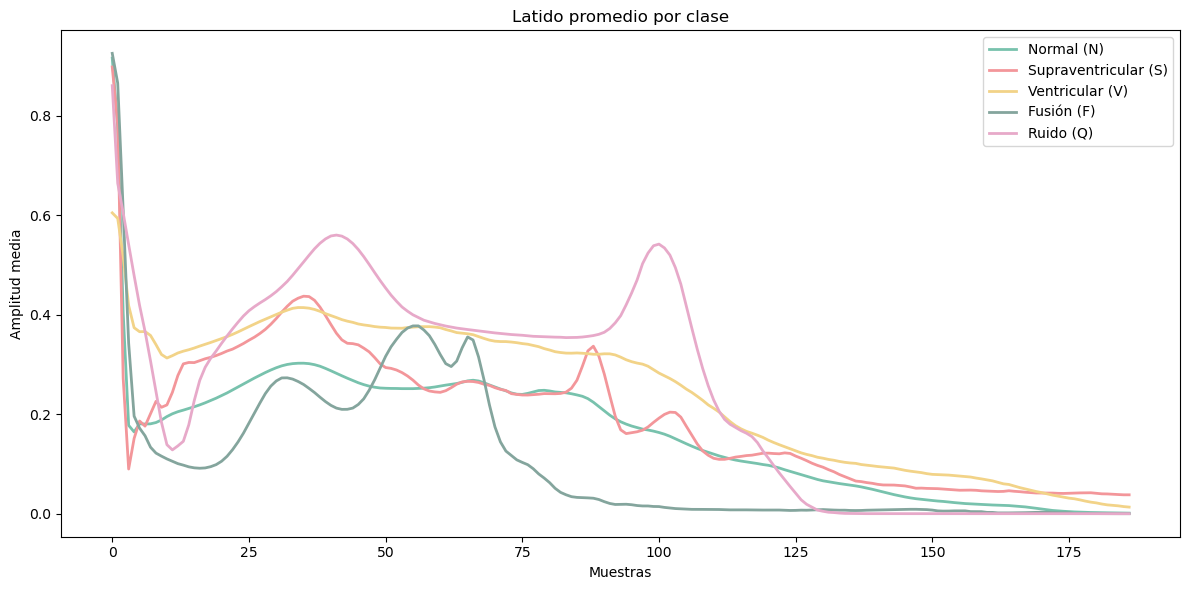

In [85]:
# Graficar latido promedio por clase
plt.figure(figsize=(12, 6))

for cls in range(5):
    mean_signal = x_train[y_train == cls].mean()
    plt.plot(mean_signal, label=class_labels[cls], color=colors[cls], linewidth=2)

plt.title('Latido promedio por clase')
plt.xlabel('Muestras')
plt.ylabel('Amplitud media')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Reducción de Dimensionalidad (PCA)
El objetivo de esta sección es identificar patrones y reducir el espacio de características. 

### 4.1 Estandarización de los datos
Aunque antes de aplicar Análisis de Componentes Principales (PCA) se suelen estandarizar las variables para evitar que dominen aquellas con mayor magnitud, en este caso se opta por mantener la normalización original de los datos [0, 1]. 

Esto se debe a que, al tratarse de señales temporales (ECG), todas las columnas representan la misma unidad y estan en una escala comparable. Aplicar una estandarización podría distorsionar la morfología de las ondas, amplificar el ruido y eliminar información de amplitud relevante para distinguir entre un latido normal y una arritmia. Por tanto, el PCA se aplicará directamente sobre los datos normalizados, permitiendo que el algoritmo capture la varianza real producida por la estructura del latido.

### 4.2 Aplicación de PCA
Se aplica PCA sobre las 187 variables del conjunto de entrenamiento, ajustando el modelo y transformando el conjunto de entrenamiento para proyectarlo al nuevo espacio de componentes principales.

In [86]:
# Aplicar PCA con todos los componentes
np.random.seed(42)
pca = PCA()
x_train_pca = pca.fit_transform(x_train)

### 4.3 Varianza explicada
Se analiza cuánta información retiene cada componente principal. El **primer componente** captura la mayor parte de la varianza (**43.51%**). Con los **10 primeros componentes** se alcanza el **78.19%** de la varianza total. Para explicar el **90%** de la varianza se necesitan **23 componentes**, y para el **95%** se requieren **36 componente**.

In [87]:
# Varianza explicada por componente
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"Varianza explicada por el primer componente: {explained_variance[0]*100:.2f}%")
print(f"Varianza explicada por los 2 primeros: {cumulative_variance[1]*100:.2f}%")
print(f"Varianza explicada por los 10 primeros: {cumulative_variance[9]*100:.2f}%")

# Componentes necesarios para el 90% y 95% 
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"\nNúmero de componentes para el 90% de varianza: {n_90}")
print(f"Número de componentes para el 95% de varianza: {n_95}")

Varianza explicada por el primer componente: 43.51%
Varianza explicada por los 2 primeros: 54.17%
Varianza explicada por los 10 primeros: 78.19%

Número de componentes para el 90% de varianza: 23
Número de componentes para el 95% de varianza: 35


El siguiente gráfico muestra la varianza explicada por cada uno de los primeros 20 componentes principales. Se observa claramente cómo el primer componente domina con un 43.51%, y a partir del segundo componente decrece rápidamente.

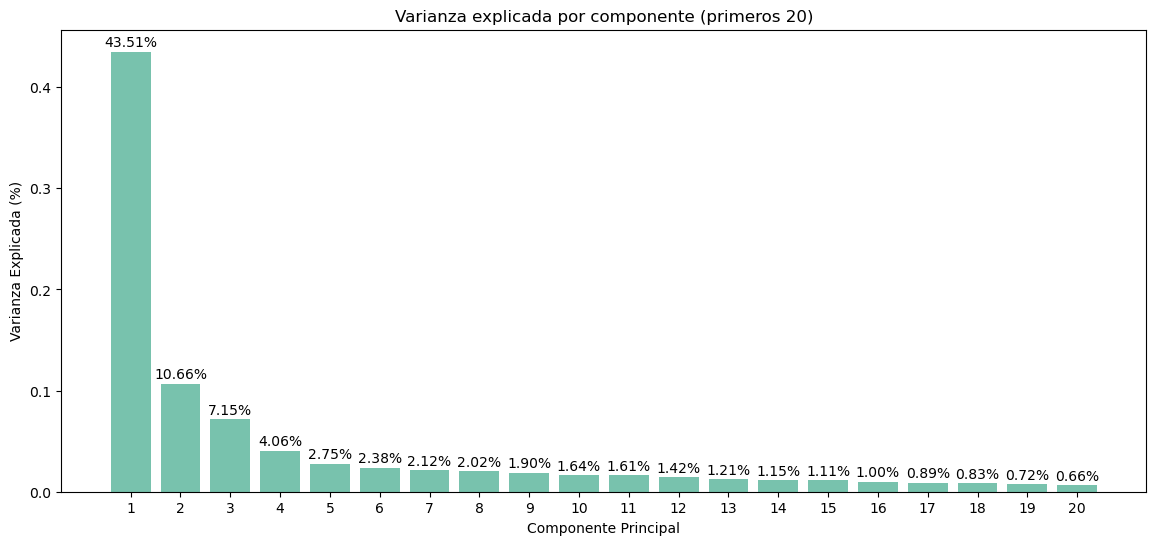

In [88]:
plt.figure(figsize=(14, 6))
plt.bar(range(1, 21), explained_variance[:20], color=colors[0])
plt.xlabel('Componente Principal')
plt.ylabel('Varianza Explicada (%)')
for i, var in enumerate(explained_variance[:20]):
    plt.text(i + 1, var + 0.005, f'{var*100:.2f}%', ha='center')
plt.title('Varianza explicada por componente (primeros 20)')
plt.xticks(range(1, 21))
plt.show()

### 4.4 Visualización en 2D (scatter plot)
A continuación se muestran dos visualizaciones para los dos primeros componente principales (PCA), que explican el **54.17%** de la varianza total. 
En la primera gráfica se confirma el **gran solapamiento** entre las clases, donde la clase Normal ocupa todo el espacio, actuando como fondo sobre el que se superponen las anomalías. Esto demuestra que no existe una frontera lineal clara que permita aislar a las clases en dos dimensiones.

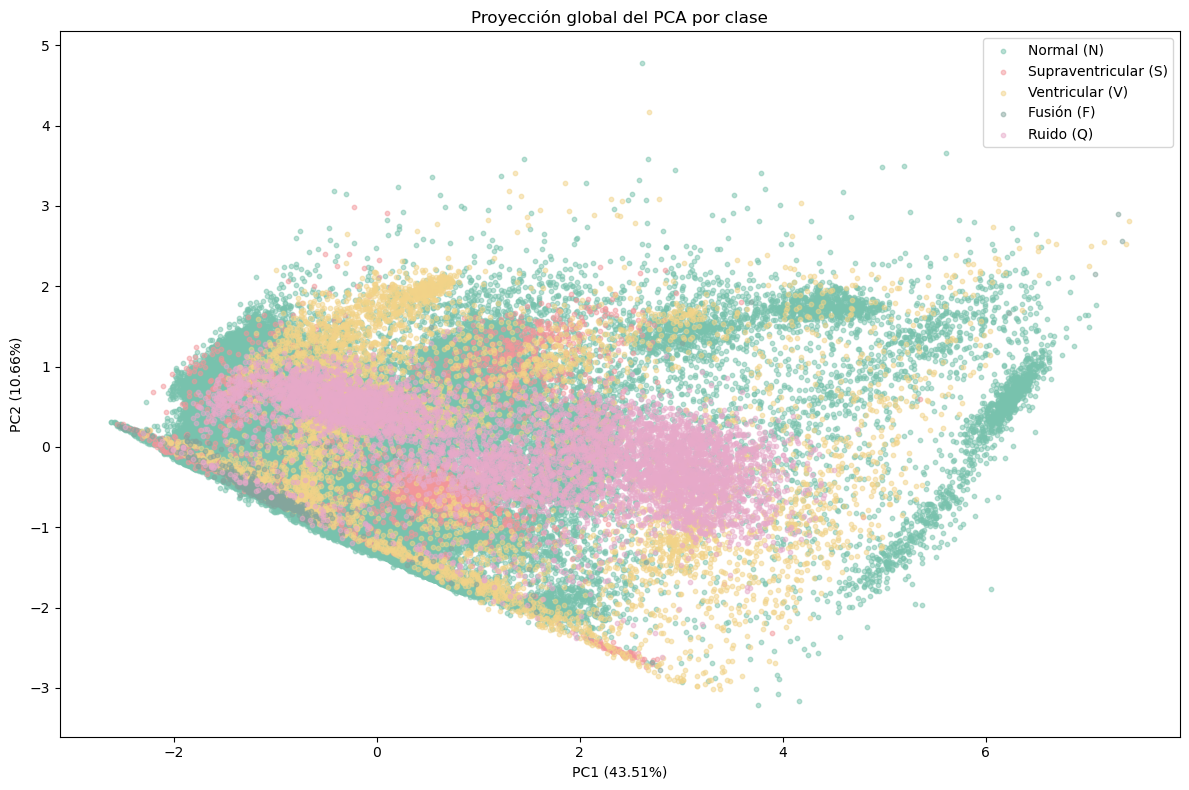

In [89]:
# Proyectar datos a 2 componentes principales
plt.figure(figsize=(12, 8))

for cls in range(5):
    mask = y_train == cls
    plt.scatter(x_train_pca[mask, 0], x_train_pca[mask, 1], 
                c=colors[cls], label=class_labels[cls], alpha=0.5, s=10)

plt.xlabel(f"PC1 ({explained_variance[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({explained_variance[1]*100:.2f}%)")
plt.title("Proyección global del PCA por clase")
plt.legend()
plt.tight_layout()
plt.show()

Para facilitar la visualización de las clases, se pinta esta segunda gráfica con los grupos separados.
- La clase Normal ocupa la mayor área, con una concentración densa en una estructura en forma de cono que se abre hacia la derecha. Su omnipresencia explica por qué es tan fácil confundir anomalías sutiles con variantes normales.
- La Supraventricular se distingue mejor en esta gráfica, donde se observa que no es una nube uniforme como parecia en el gráfico global, sino que se divide en múltiples sub-agrupaciones. Se distinguen al menos dos núcleos principales y una estela diagonal inferior, lo que sugiere que esta categoría engloba subtipos morfológicos distintos.
- La clase Ventricular muestra una dispersión muy amplia y difusa, similar a la normal. A diferencia del ruido, no está compactada, lo que refleja gran variabilidad en la forma de los latidos ventriculares.
- Fusión presenta el comportamiento más singular. Sus puntos se alinean en una trayectoria diagonal compacta en la zona inferior izquierda (PC1 < 0, PC2 < 1), comportándose casi como una línea, lo que indica una estructura más rígida y característica.
- El Ruido se manifiesta como una nube densa y central, más compacta que las arritmias reales.

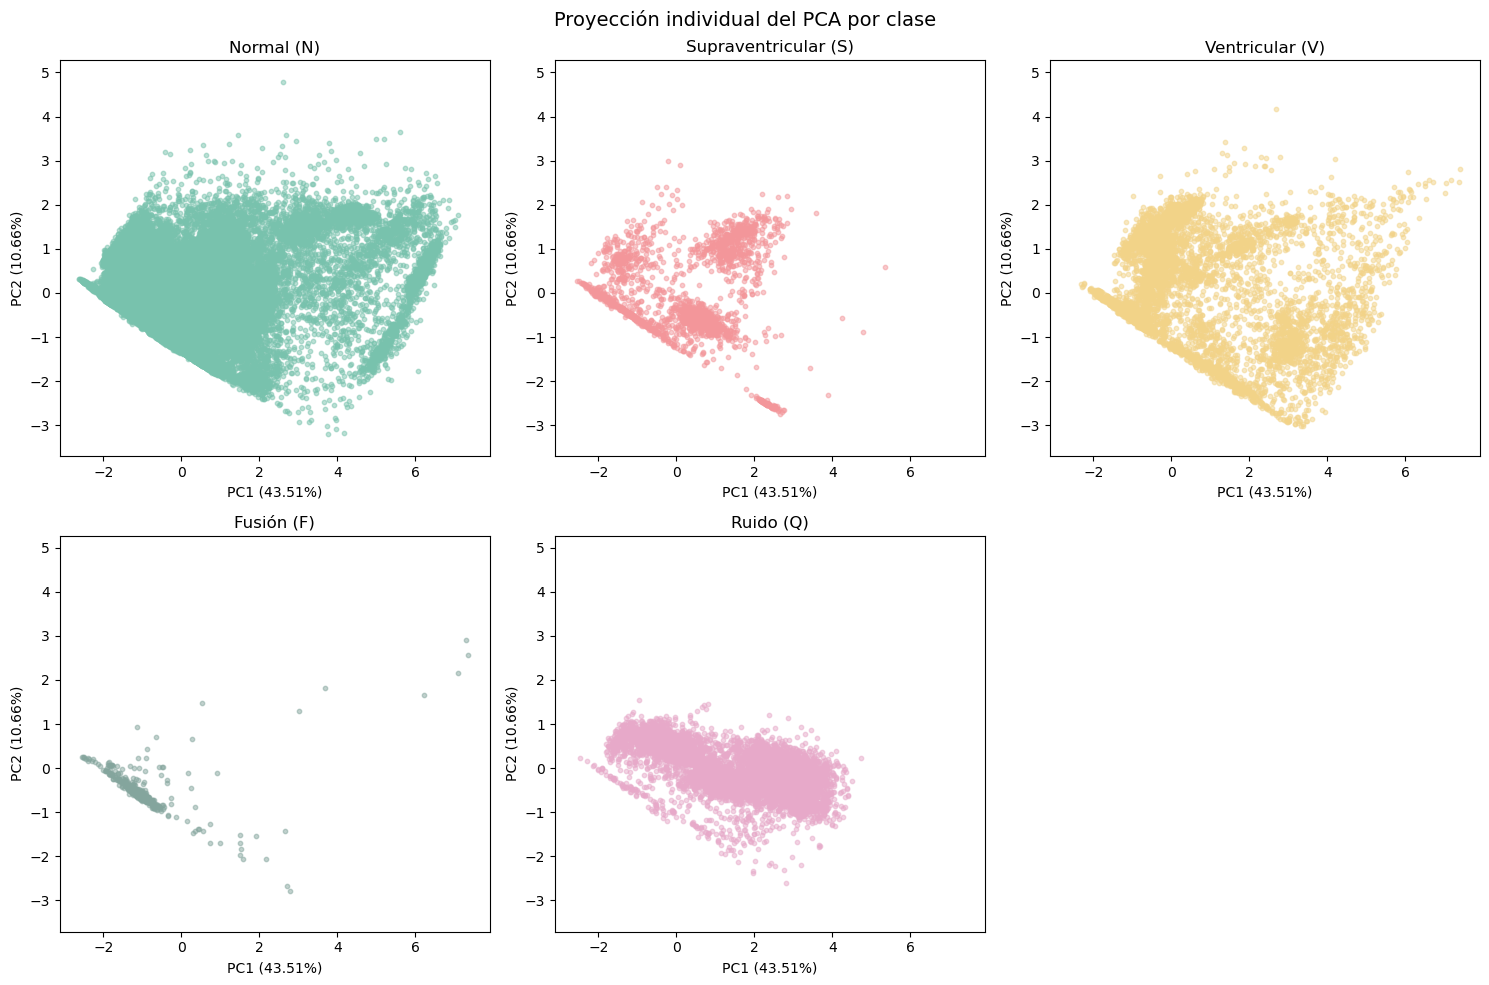

In [90]:
# Proyección PCA - un gráfico por clase
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for cls in range(5):
    ax = axes[cls]
    mask = y_train == cls
    ax.scatter(x_train_pca[mask, 0], x_train_pca[mask, 1], 
               c=colors[cls], alpha=0.5, s=10)
    ax.set_xlabel(f"PC1 ({explained_variance[0]*100:.2f}%)")
    ax.set_ylabel(f"PC2 ({explained_variance[1]*100:.2f}%)")
    ax.set_title(f"{class_labels[cls]}")
    ax.set_xlim(x_train_pca[:, 0].min() - 0.5, x_train_pca[:, 0].max() + 0.5)
    ax.set_ylim(x_train_pca[:, 1].min() - 0.5, x_train_pca[:, 1].max() + 0.5)

# Ocultar el sexto subplot vacío
axes[5].axis('off')

plt.suptitle("Proyección individual del PCA por clase", fontsize=14)
plt.tight_layout()
plt.show()

La visualización desglosada demuestra que, aunque hay solapamiento, las clases tienen topologías internas distintas (líneas diagonales en Fusión, islas en Supraventricular, dispersión en Ventricular). Esto refuerza la hipótesis de que un modelo no lineal (Deep Learning) podrá explotar estas diferencias estructurales para clasificar correctamente, algo que un modelo lineal simple no podría lograr.

## 5. Modelos de Clasificación
A partir de esta sección, se trabaja exclusivamente con las etiquetas binarias (`y_train_binary`, `y_test_binary`), donde la clase **Anómalo (1)** agrupa todas las arritmias y la clase **Normal (0)** representa los latidos sanos. El objetivo es detectar anomalías, por lo que la clase de interes es la clase 1.

Se implementan varios algoritmos clásicos de clasificación supervisada como regresión logística, árboles de decisión, clasificadores bayesianos y redes neuronales tipo MLP, para comparar su rendimiento en la identificación. Para evaluar el desempeño de cada modelo se emplean métricas orientadas a la detección de la clase positiva:
- Precision: Proporción de predicciones de anomalía que son correctas (evitar falsos positivos).
- Recall: Proporción de anomalías reales que son detectadas (evitar falsos negativos)
- F1-score: Media armónica entre precision y recall

Las matrices de confusión se presentan con Anómalo en primera fila/columna, de modo que la esquina superior izquierda muestra los verdaderos positivos o anomalías correctamente detectadas.

### 5.1 Modelo 1: Regresión Logística

In [91]:
# Entrenamiento
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(x_train, y_train_binary)
predict_lr = lr_model.predict(x_test)

El modelo de Regresión Logística, obtiene un buen accuracy (91%). Sin embargo, su recall es bajo (55%), lo que significa que solo detecta la mitad de las arritmias reales. Este comportamiento se debe al desbalance que se observo durante el EDA, el modelo tiende a predecir la clase mayoritaria (Normal). La precisión (85%) indica que cuando predice una arritmia, suele acertar, pero el problema es que deja muchas sin detectar.

              precision    recall  f1-score   support

     Anómalo       0.85      0.55      0.67      3774
      Normal       0.91      0.98      0.94     18118

    accuracy                           0.91     21892
   macro avg       0.88      0.76      0.81     21892
weighted avg       0.90      0.91      0.90     21892



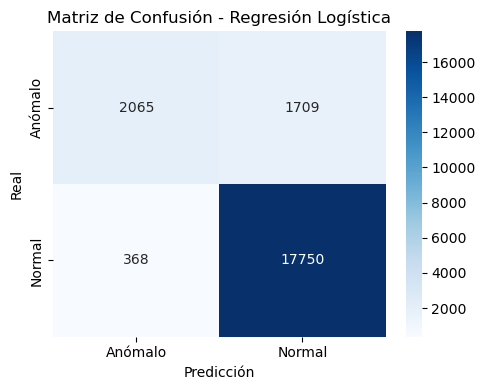

In [92]:
# Evaluación
print(classification_report(y_test_binary, predict_lr, labels=[1, 0], target_names=['Anómalo', 'Normal'])) 

cm_lr = confusion_matrix(y_test_binary, predict_lr, labels=[1, 0])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap="Blues", xticklabels=['Anómalo', 'Normal'], yticklabels=['Anómalo', 'Normal'])
plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

### 5.2 Modelo 2: Árbol de Decisión

In [93]:
# Entrenamiento
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train_binary)
predict_dt = dt_model.predict(x_test)

El Árbol de Decisión presenta un accuracy bastante alto (96%), al igual que su recall (89%) que supera a la Regresión Logística. Esto indica que el árbol es capaz de identificar patrones no lineales en las señales ECG que permiten distinguir mejor las arritmias. Su precision (89%) mantiene un buen equilibrio y también con un buen F1-Score (89%). Una ventaja adicional de este modelo es su interpretabilidad ya que pueden visualizarse y explicarse, lo cual es importante en contextos clínicos donde es necesario justificar los diagnósticos.

              precision    recall  f1-score   support

     Anómalo       0.89      0.89      0.89      3774
      Normal       0.98      0.98      0.98     18118

    accuracy                           0.96     21892
   macro avg       0.93      0.93      0.93     21892
weighted avg       0.96      0.96      0.96     21892



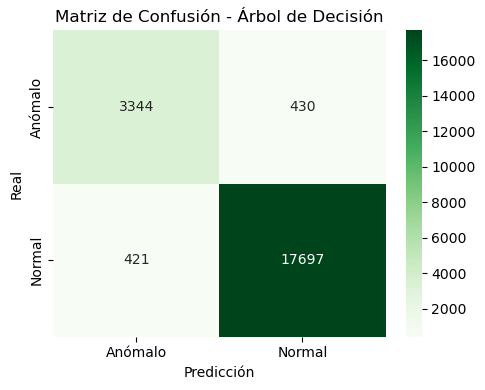

In [94]:
# Evaluación
print(classification_report(y_test_binary, predict_dt, labels=[1, 0], target_names=['Anómalo', 'Normal']))

cm_dt = confusion_matrix(y_test_binary, predict_dt, labels=[1, 0])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', xticklabels=['Anómalo', 'Normal'], yticklabels=['Anómalo', 'Normal'])
plt.title('Matriz de Confusión - Árbol de Decisión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

### 5.3 Modelo 3: Clasificador Naive Bayes

In [95]:
# Entrenamiento
nb_model = GaussianNB()
nb_model.fit(x_train, y_train_binary)
predict_nb = nb_model.predict(x_test)

El clasificador Naive Bayes se basa en el Teorema de Bayes asumiendo independencia condicional entre las características. Sin embargo, esta suposición no es realista para señales ECG, donde las 187 muestras temporales están fuertemente correlacionadas entre sí, ya que cada punto de la señal depende de los anteriores. Como consecuencia, este modelo obtiene los peores resultados de todos los evaluados: un accuracy del 81% y un F1-Score de apenas 47%. La precision baja (45%) indica que genera muchos falsos positivos, mientras que el recall del 49% significa que deja sin detectar aproximadamente la mitad de las arritmias. Estos resultados confirman que el supuesto de independencia afecta fuertemente el rendimiento del modelo.

              precision    recall  f1-score   support

     Anómalo       0.45      0.49      0.47      3774
      Normal       0.89      0.88      0.88     18118

    accuracy                           0.81     21892
   macro avg       0.67      0.68      0.68     21892
weighted avg       0.82      0.81      0.81     21892



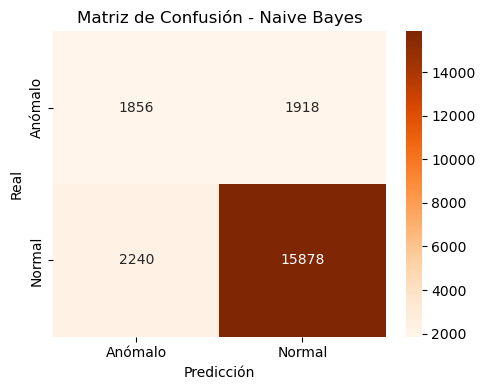

In [96]:
# Evaluación
print(classification_report(y_test_binary, predict_nb, labels=[1, 0], target_names=['Anómalo', 'Normal']))

cm_nb = confusion_matrix(y_test_binary, predict_nb, labels=[1, 0])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', xticklabels=['Anómalo', 'Normal'], yticklabels=['Anómalo', 'Normal'])
plt.title('Matriz de Confusión - Naive Bayes')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

### 5.4 Modelo 4: Red Neuronal (MLP)

In [97]:
# Entrenamiento
mlp_model = MLPClassifier(
  hidden_layer_sizes=(64, 32), 
  max_iter=200, 
  early_stopping=True, 
  learning_rate='adaptive', learning_rate_init=0.001, 
  random_state=42
)
mlp_model.fit(x_train, y_train_binary)
predict_mlp = mlp_model.predict(x_test)

La Red Neuronal Multicapa (MLP) es un modelo capaz de aprender representaciones no lineales complejas mediante capas ocultas de neuronas. La arquitectura utilizada (64 neuronas en la primera capa, 32 en la segunda) permite capturar patrones complejos en las señales ECG. Este modelo obtiene los mejores resultados en todas las métricas: un accuracy del 98% indica que clasifica correctamente casi todos los latidos; una precision del 97% muestra que cuando predice una arritmia, suele acertar, minimizando los falsos positivos; el recall del 90% demuestra que detecta la mayoría de las arritmias reales, un aspecto crítico en aplicaciones clínicas; y el F1-Score del 94% resume el equilibrio óptimo entre precision y recall alcanzado de entre todos los modelos.

              precision    recall  f1-score   support

     Anómalo       0.97      0.90      0.94      3774
      Normal       0.98      0.99      0.99     18118

    accuracy                           0.98     21892
   macro avg       0.98      0.95      0.96     21892
weighted avg       0.98      0.98      0.98     21892



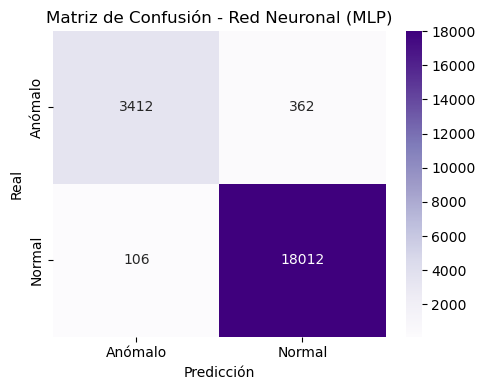

In [98]:
# Evaluación
print(classification_report(y_test_binary, predict_mlp, labels=[1, 0], target_names=['Anómalo', 'Normal']))

cm_mlp = confusion_matrix(y_test_binary, predict_mlp, labels=[1, 0])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Purples', xticklabels=['Anómalo', 'Normal'], yticklabels=['Anómalo', 'Normal'])
plt.title('Matriz de Confusión - Red Neuronal (MLP)')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

### 5.6 Comparativa de modelos

In [99]:
# Tabla comparativa
models = ['Regresión logística', 'Árbol de decisión', 'Naive Bayes', 'Red neuronal (MLP)']
predictions = [predict_lr, predict_dt, predict_nb, predict_mlp]

results = []
for name, pred in zip(models, predictions):
  results.append({
    'Modelo': name,
    'Accuracy': accuracy_score(y_test_binary, pred),
    'Precision': precision_score(y_test_binary, pred),
    'Recall': recall_score(y_test_binary, pred),
    'F1-Score': f1_score(y_test_binary, pred)
  })

df_results = pd.DataFrame(results)
df_results.set_index('Modelo')

,Accuracy,Precision,Recall,F1-Score
Modelo,,,,
Regresión logística,0.905125,0.848746,0.547165,0.665378
Árbol de decisión,0.961127,0.888181,0.886063,0.887120
Naive Bayes,0.810068,0.453125,0.491786,0.471665
Red neuronal (MLP),0.978622,0.969869,0.904081,0.935820


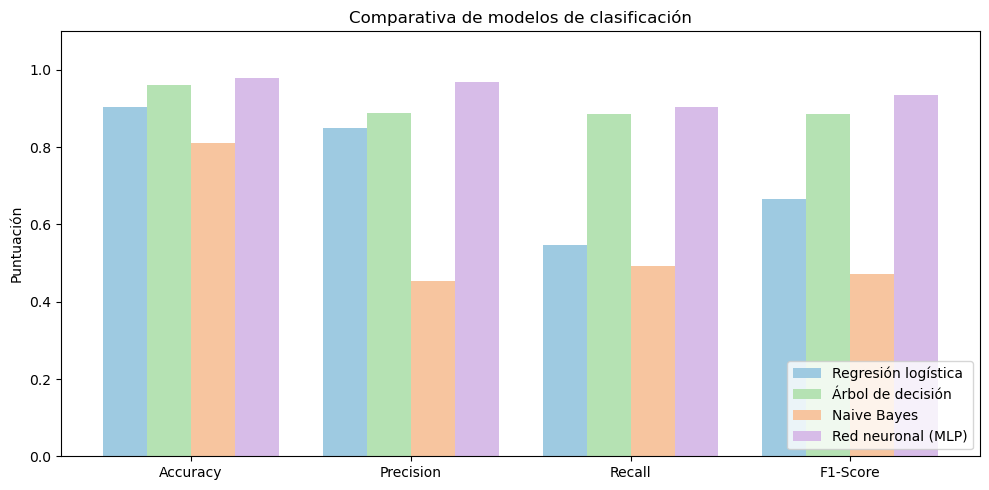

In [100]:
# Gráfica comparativa
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))

for i, (model, color) in enumerate(zip(models, model_colors)):
  values = df_results[df_results['Modelo'] == model][metrics].values[0]
  bars = ax.bar(x + i*width, values, width, label=model, color=color)

ax.set_ylabel('Puntuación')
ax.set_title('Comparativa de modelos de clasificación')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.legend(loc='lower right')
ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

### 5.7 Análisis y selección del mejor modelo
La Red Neuronal (MLP) es la que consigue el mejor clasificador, superando al resto en todas las métricas evaluadas y el Árbol de Decisión resulta una buena alternativa con la ventaja de ser interpretable. Por su parte, la Regresión Logística, aunque aceptable en accuracy, muestra limitaciones debido al desbalance de clases; y Naive Bayes obtiene los peores resultados debido a la suposición de independencia.

En un sistema de alerta para detección de arritmias, el recall es la métrica más crítica. En el contexto médico, es preferible generar algunas alertas innecesarias (falsos positivos) que pueden ser descartadas por un profesional, a no detectar una arritmia real (falso negativo), ya que esto último podría tener consecuencias graves para el paciente. Un falso negativo significa que un paciente con una condición cardíaca potencialmente peligrosa no recibiría la atención necesaria.

Por tanto, se selecciona la **Red Neuronal (MLP)** como el mejor modelo para un sistema de monitorización clínica. Este modelo maximiza tanto el recall (90.41%) como la precision (96.99%), ofreciendo el mejor equilibrio para detectar arritmias de forma fiable mientras mantiene una baja tasa de falsas alarmas que podrían saturar los sistemas de alerta.

## 6. Probabilidades Condicionales y Teorema de Bayes
El objetivo de esta sección es aplicar el teorema de Bayes para estimar la probabilidad de que un latido sea anómalo dado cierto patrón de señal.

### 6.1 Selección de datos: Normal vs Anómalo

Para aplicar el Teorema de Bayes, se utilizan las clases binarias ya definidas: clase 0 (latidos normales) y clase 1 (latidos anómalos, que agrupa todas las arritmias).

In [101]:
# Utilizar clasificación binaria: Normal (0) vs Anómalo (1)
x_bayes = x_train
y_bayes = y_train_binary

# Verificar distribución
n_clase_0 = (y_bayes == 0).sum()
n_clase_1 = (y_bayes == 1).sum()
n_total = len(y_bayes)

print(f"Total de registros: {n_total}")
print(f"Clase 0 (Normal): {n_clase_0} ({n_clase_0 / n_total * 100:.2f}%)")
print(f"Clase 1 (Anómalo): {n_clase_1} ({n_clase_1 / n_total * 100:.2f}%)")

Total de registros: 87554
Clase 0 (Normal): 72471 (82.77%)
Clase 1 (Anómalo): 15083 (17.23%)


### 6.2 Cálculo de probabilidades marginales y condicionales
Las **probabilidades marginales** representan la frecuencia relativa de cada clase en el conjunto de entrenamiento. P(Clase 0) indica la proporción de latidos normales y P(Clase 1) la proporción de latidos anómalos. Como ya se observó en el análisis exploratorio, existe un desbalance significativo: los latidos normales representan aproximadamente el 83% mientras que los anómalos solo el 17%.

In [102]:
# Probabilidades marginales
P_clase_0 = n_clase_0 / n_total
P_clase_1 = n_clase_1 / n_total

print("Probabilidades marginales")
print(f"P(Normal) = {n_clase_0} / {n_total} = {P_clase_0:.4f}")
print(f"P(Anómalo) = {n_clase_1} / {n_total} = {P_clase_1:.4f}")

Probabilidades marginales
P(Normal) = 72471 / 87554 = 0.8277
P(Anómalo) = 15083 / 87554 = 0.1723


Para calcular **probabilidades condicionales**, se define un patrón observable X basado en la **desviación estándar (variabilidad) de cada latido**. Un latido presenta el patrón X si su desviación estándar es igual o superior a la mediana de la desviación estándar de todo el conjunto. Como se observó en el análisis exploratorio, los latidos anómalos presentan en promedio una desviación estándar de 0.188, superior a la de los normales (0.168), por lo que este patrón debería ser un posible valor discriminativo.

In [103]:
# Definir patrón X basado en desviación estándar (variabilidad)
desv_est = x_bayes.std(axis=1)
umbral = desv_est.median()  # Usar la mediana como umbral
patron_X = desv_est >= umbral

# Probabilidades condicionales P(X | Clase)
X_en_clase_0 = ((y_bayes == 0) & patron_X).sum()
X_en_clase_1 = ((y_bayes == 1) & patron_X).sum()

P_X_dado_clase_0 = X_en_clase_0 / n_clase_0
P_X_dado_clase_1 = X_en_clase_1 / n_clase_1

print(f"Patrón X: desviación estándar >= {umbral:.6f} (mediana)")
print("\nEstadísticos de desviación estándar por clase:")
desv_normal = x_bayes[y_bayes == 0].std(axis=1).mean()
desv_anomalo = x_bayes[y_bayes == 1].std(axis=1).mean()
print(f"  - Normal (media): {desv_normal:.6f}")
print(f"  - Anómalo (media): {desv_anomalo:.6f}")
print(f"\nProbabilidades condicionales (Verosimilitudes)")
print(f"P(X | Normal) = {X_en_clase_0} / {n_clase_0} = {P_X_dado_clase_0:.4f}")
print(f"P(X | Anómalo) = {X_en_clase_1} / {n_clase_1} = {P_X_dado_clase_1:.4f}")

Patrón X: desviación estándar >= 0.180816 (mediana)

Estadísticos de desviación estándar por clase:
  - Normal (media): 0.186645
  - Anómalo (media): 0.226565

Probabilidades condicionales (Verosimilitudes)
P(X | Normal) = 33054 / 72471 = 0.4561
P(X | Anómalo) = 10723 / 15083 = 0.7109


### 6.3 Estimación manual con el Teorema de Bayes

El **Teorema de Bayes** permite calcular la probabilidad de una clase dado un patrón observado (probabilidad a posteriori), combinando la información previa sobre la frecuencia de las clases con la evidencia proporcionada por el patrón:

$$P(\text{Clase} | X) = \frac{P(X | \text{Clase}) \cdot P(\text{Clase})}{P(X)}$$

Donde:
- $P(\text{Clase})$ es la **probabilidad a priori** (frecuencia de la clase en el dataset)
- $P(X | \text{Clase})$ es la **verosimilitud** (probabilidad de observar el patrón dado la clase)
- $P(X)$ es la **probabilidad marginal del patrón** (normalización)
- $P(\text{Clase} | X)$ es la **probabilidad a posteriori** (lo que queremos estimar)

La probabilidad marginal $P(X)$ se calcula mediante la **ley de probabilidad total**:

$$P(X) = P(X|\text{Normal}) \cdot P(\text{Normal}) + P(X|\text{Anómalo}) \cdot P(\text{Anómalo})$$

El resultado de $P(X)$ indica el porcentaje de latidos que presenta el patrón X (desviación estándar ≥ mediana). Este patrón debería mostrar diferencias significativas entre clases, ya que la desviación estándar es una medida de variabilidad que efectivamente distingue entre latidos normales y anómalos.

In [104]:
# P(X) - probabilidad total del patrón
P_X = P_X_dado_clase_0 * P_clase_0 + P_X_dado_clase_1 * P_clase_1

print("Aplicación del Teorema de Bayes")
print(f"P(X) = P(X|Normal) x P(Normal) + P(X|Anómalo) x P(Anómalo)")
print(f"P(X) = {P_X_dado_clase_0:.4f} x {P_clase_0:.4f} + {P_X_dado_clase_1:.4f} x {P_clase_1:.4f}")
print(f"P(X) = {P_X:.4f}")
print()

Aplicación del Teorema de Bayes
P(X) = P(X|Normal) x P(Normal) + P(X|Anómalo) x P(Anómalo)
P(X) = 0.4561 x 0.8277 + 0.7109 x 0.1723
P(X) = 0.5000



Se calcula $P(\text{Normal} | X)$, como la probabilidad de que un latido sea **normal** dado que presenta el patrón X.

In [105]:
# P(Normal | X)
P_clase_0_dado_X = (P_X_dado_clase_0 * P_clase_0) / P_X
print("P(Normal | X) = P(X|Normal) x P(Normal) / P(X)")
print(f"P(Normal | X) = {P_X_dado_clase_0:.4f} x {P_clase_0:.4f} / {P_X:.4f}")
print(f"P(Normal | X) = {P_clase_0_dado_X:.4f}")
print()

P(Normal | X) = P(X|Normal) x P(Normal) / P(X)
P(Normal | X) = 0.4561 x 0.8277 / 0.5000
P(Normal | X) = 0.7551



De la misma manera, se calcula $P(\text{Anómalo} | X)$, como la probabilidad de que un latido sea **anómalo** dado que presenta el patrón X.

In [106]:
# P(Anómalo | X)
P_clase_1_dado_X = (P_X_dado_clase_1 * P_clase_1) / P_X
print("P(Anómalo | X) = P(X|Anómalo) x P(Anómalo) / P(X)")
print(f"P(Anómalo | X) = {P_X_dado_clase_1:.4f} x {P_clase_1:.4f} / {P_X:.4f}")
print(f"P(Anómalo | X) = {P_clase_1_dado_X:.4f}")
print()

P(Anómalo | X) = P(X|Anómalo) x P(Anómalo) / P(X)
P(Anómalo | X) = 0.7109 x 0.1723 / 0.5000
P(Anómalo | X) = 0.2449



Finalmente, se verifica que las probabilidades a posteriori suman 1, cumpliendo que $P(\text{Normal} | X) + P(\text{Anómalo} | X) = 1$.

In [107]:
print(f"Verificación: P(Normal|X) + P(Anómalo|X) = {P_clase_0_dado_X + P_clase_1_dado_X:.4f}")

Verificación: P(Normal|X) + P(Anómalo|X) = 1.0000


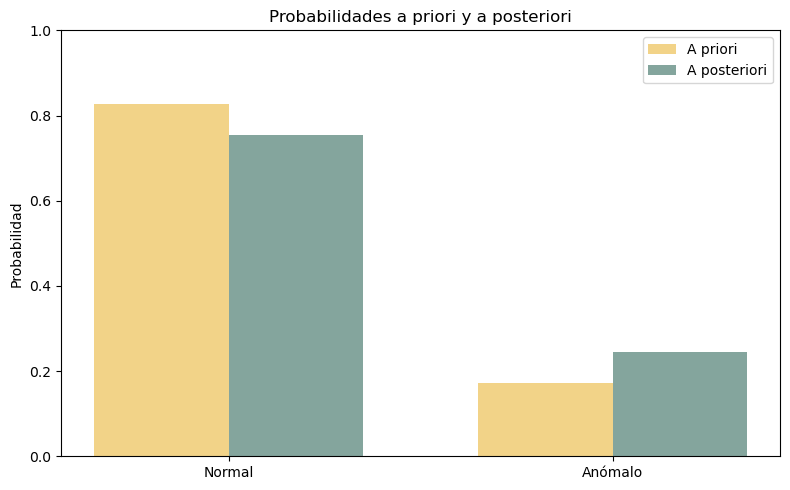

In [108]:
# grafica de barras de las probabilidades a priori y posteriori
labels = ['Normal', 'Anómalo']
prior_probs = [P_clase_0, P_clase_1]
posterior_probs = [P_clase_0_dado_X, P_clase_1_dado_X]
x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, prior_probs, width, label='A priori', color=colors[2])
bars2 = ax.bar(x + width/2, posterior_probs, width, label='A posteriori', color=colors[3])
ax.set_ylabel('Probabilidad')
ax.set_title('Probabilidades a priori y a posteriori')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 6.4 Justificación e interpretación
Con el patrón X (desviación estándar ≥ mediana) se obtienen:
- P(Normal | X) = 0.7551
- P(Anómalo | X) = 0.2449

El patrón aumenta la probabilidad de anomalía desde **0.1723 (a priori)** hasta **0.2449 (a posteriori)**, lo que indica que aporta información aunque de forma limitada. La razón de verosimilitud asociada al patrón es **baja (1.56)**, lo que significa que la presencia de alta variabilidad hace que el registro sea ligeramente más compatibles con latido anómalo que con uno normal. 

Desde el punto de vista clínico, esto implica que la desviación estandar **sí capta cierta tendencia hacia anomalía**, pero no separa de forma clara las clases. Esto se debe principalmente la desbalance, ya que un latido con alta variabilidad sigue siendo más probable que sea normal, debido al predominio de estos en el conjunto de datos. Por ello, la desviación estándar, puede considerarse un **indicador complementario** y no un critería fiable por si solo, sería aconsejable combinarlo con otras características del latido para mejorar la capacidad de detección.